In [ ]:
!pip install -q faiss-cpu gradio datasets

In [ ]:
import torch
import numpy as np
import faiss
from datasets import load_dataset
from transformers import CLIPModel, CLIPProcessor
from tqdm.auto import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

MODEL_NAME = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(MODEL_NAME).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL_NAME)


ds = load_dataset("jxie/flickr8k", split="test")
print(ds)
print(ds.column_names)

Device: cuda


Dataset({
    features: ['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4'],
    num_rows: 1000
})
['image', 'caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4']


In [ ]:
def _to_tensor(x):
    # Compatibility across transformers versions
    return x if torch.is_tensor(x) else x.pooler_output

@torch.no_grad()
def embed_images(dataset, batch_size=64):
    all_feats = []
    for i in tqdm(range(0, len(dataset), batch_size), desc="Embedding images"):
        images = [im.convert("RGB") for im in dataset[i:i + batch_size]["image"]]
        inputs = processor(images=images, return_tensors="pt").to(device)
        feats = _to_tensor(model.get_image_features(**inputs))
        feats = feats / feats.norm(dim=-1, keepdim=True)
        all_feats.append(feats.cpu().numpy())
    return np.concatenate(all_feats).astype("float32")

@torch.no_grad()
def embed_texts(texts, batch_size=256):
    all_feats = []
    for i in range(0, len(texts), batch_size):
        inputs = processor(text=texts[i:i + batch_size], return_tensors="pt",
                           padding=True, truncation=True, max_length=77).to(device)
        feats = _to_tensor(model.get_text_features(**inputs))
        feats = feats / feats.norm(dim=-1, keepdim=True)
        all_feats.append(feats.cpu().numpy())
    return np.concatenate(all_feats).astype("float32")

image_embeddings = embed_images(ds)
print("Image embeddings:", image_embeddings.shape)

index = faiss.IndexFlatIP(image_embeddings.shape[1])  # inner product = cosine (vectors are normalized)
index.add(image_embeddings)
print("Index size:", index.ntotal)

np.save("image_embeddings.npy", image_embeddings)

Image embeddings: (1000, 512)
Index size: 1000


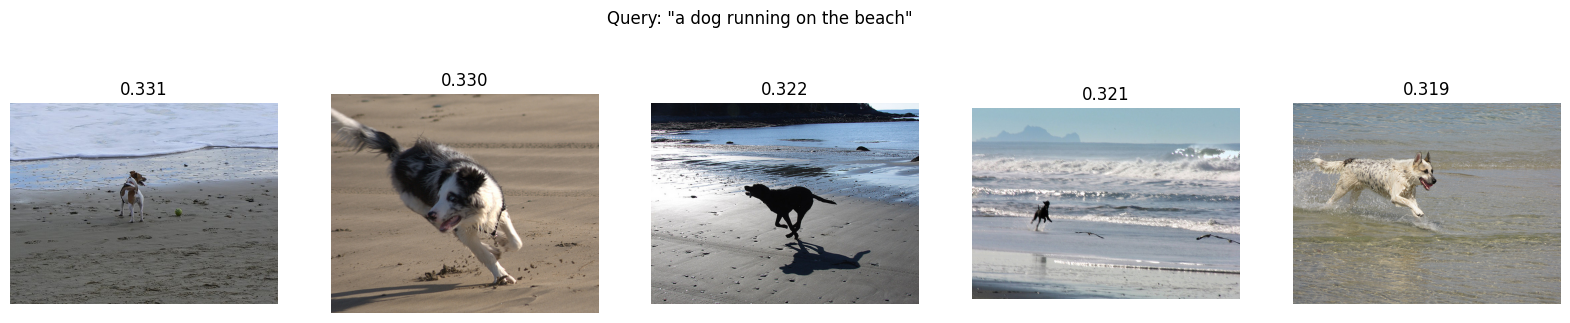

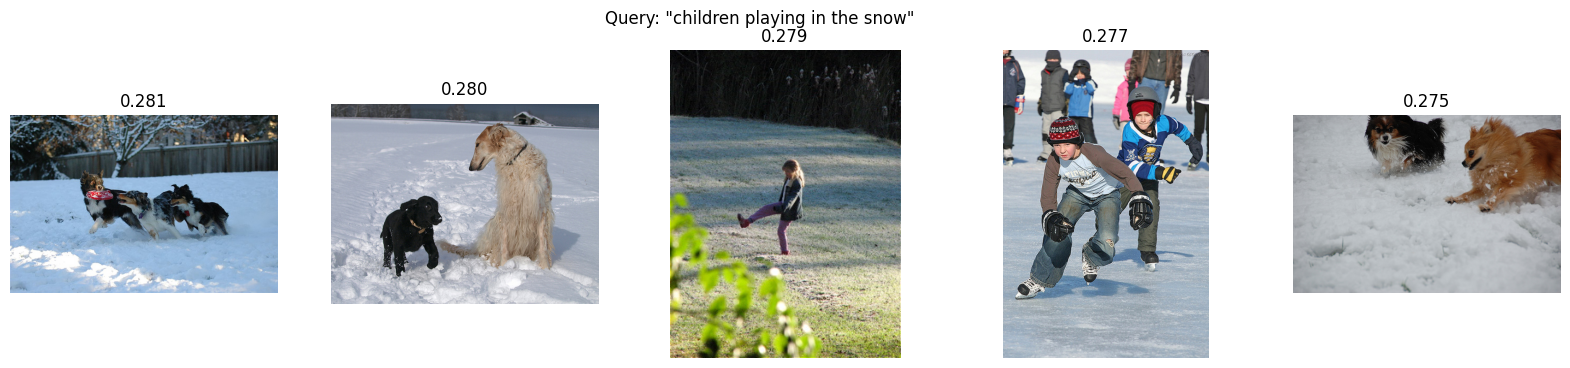

In [ ]:
def search(query, k=5):
    q = embed_texts([query])
    scores, ids = index.search(q, k)
    return [(ds[int(i)]["image"], float(s)) for s, i in zip(scores[0], ids[0])]

import matplotlib.pyplot as plt

def show_results(query, k=5):
    results = search(query, k)
    fig, axes = plt.subplots(1, k, figsize=(4 * k, 4))
    for ax, (img, score) in zip(np.atleast_1d(axes), results):
        ax.imshow(img)
        ax.set_title(f"{score:.3f}")
        ax.axis("off")
    fig.suptitle(f'Query: "{query}"')
    plt.show()

show_results("a dog running on the beach")
show_results("children playing in the snow")

In [ ]:
caption_cols = [c for c in ds.column_names if c.startswith("caption")]
print("Caption columns:", caption_cols)

captions, gt_image_ids = [], []
for i in range(len(ds)):
    row = ds[i]
    for c in caption_cols:
        captions.append(row[c])
        gt_image_ids.append(i)

text_embeddings = embed_texts(captions)
sims = text_embeddings @ image_embeddings.T  # (num_captions, num_images)

gt_image_ids = np.array(gt_image_ids)
gt_scores = sims[np.arange(len(captions)), gt_image_ids][:, None]
ranks = (sims > gt_scores).sum(axis=1)  # 0 = correct image ranked first

results = {}
for k in [1, 5, 10]:
    results[f"Recall@{k}"] = float((ranks < k).mean() * 100)

print(f"Model: {MODEL_NAME}")
for name, value in results.items():
    print(f"{name}: {value:.2f}%")

Caption columns: ['caption_0', 'caption_1', 'caption_2', 'caption_3', 'caption_4']
Model: openai/clip-vit-base-patch32
Recall@1: 53.76%
Recall@5: 80.80%
Recall@10: 88.86%


In [ ]:
import gradio as gr
from PIL import Image

def search_flickr(query, k):
    if not query.strip():
        return []
    return [(img, f"score: {s:.3f}") for img, s in search(query, int(k))]

def build_user_index(files):
    if not files:
        return None, "Please upload at least one image."
    paths = [f if isinstance(f, str) else f.name for f in files]
    images = [Image.open(p).convert("RGB") for p in paths]
    feats = []
    with torch.no_grad():
        for i in range(0, len(images), 32):
            inputs = processor(images=images[i:i + 32], return_tensors="pt").to(device)
            f = _to_tensor(model.get_image_features(**inputs))
            f = f / f.norm(dim=-1, keepdim=True)
            feats.append(f.cpu().numpy())
    emb = np.concatenate(feats).astype("float32")
    return {"emb": emb, "paths": paths}, f"Indexed {len(paths)} images. Now type a query."

def search_user(query, k, state):
    if state is None or not query.strip():
        return []
    q = embed_texts([query])[0]
    sims = state["emb"] @ q
    top = np.argsort(-sims)[:int(k)]
    return [(Image.open(state["paths"][i]).convert("RGB"), f"score: {sims[i]:.3f}") for i in top]

with gr.Blocks(title="Text-to-Image Search with CLIP") as demo:
    gr.Markdown("# Text-to-Image Search with CLIP\nType an English description and find the best matching images.")

    with gr.Tab("Flickr8k dataset"):
        q1 = gr.Textbox(label="Text query", placeholder="e.g. a dog running on the beach")
        k1 = gr.Slider(1, 12, value=6, step=1, label="Number of results")
        btn1 = gr.Button("Search")
        out1 = gr.Gallery(label="Top matches", columns=3)
        btn1.click(search_flickr, [q1, k1], out1)

    with gr.Tab("Your own images"):
        files = gr.Files(label="Upload your images", file_types=["image"])
        build_btn = gr.Button("Build index")
        status = gr.Textbox(label="Status", interactive=False)
        user_state = gr.State(None)
        build_btn.click(build_user_index, files, [user_state, status])

        q2 = gr.Textbox(label="Text query", placeholder="e.g. a person smiling")
        k2 = gr.Slider(1, 12, value=6, step=1, label="Number of results")
        btn2 = gr.Button("Search")
        out2 = gr.Gallery(label="Top matches", columns=3)
        btn2.click(search_user, [q2, k2, user_state], out2)

demo.launch(share=True, debug=True)